## Testing rotation and projection convention
---

In this notebook I am trying to test that the conventions I'm using for rotating the numpy voxel array match the Cartesian right hand grid we use to define the algorithm in the document. (this is mostly for debugging)

Numpy indexing is referred to as axis 0 = z (depth), axis 1 = y (height), axis 2 = (width), where axes show the "positive" direction

```
(Cartesian RHG)

  (z)                       
   |
   |
   |__ __ __ (y)
  /
 / 
(x)

(Numpy LHG)

   (z)
   /
  /
 /__ __ __ (x)
|
|
|
(y)
```

In our definitions, we consider the projection to be to the <span style="color:red; font-weight:bold">z-axis</span> after rotation by polar angle *$\theta$* and azimuthal angle $\varphi$. (skipping $\omega$ for now). I think this would correspond to numpy y-axis or np.sum(volume, axis=(0,2)).

Using fiNUFFT, I *think* I am computing y => Fourier points, x => $\theta$ and z => $\varphi$ in the Numpy conventions. So the test I am trying here is:
1) compute projection tensor of $f$ as $\mathbb{R}^{n_\varphi \times n_p \times n_\theta}$
2) rotate $f$ so that $g = R_{\theta,\varphi}f$ (check visually by plotting orthogonal projection plots to see if rotations makes sense in RHG)
3) check if closest 1D slice from projection tensor matches the real space rotation and projection to 1D of $f$

So far I think things are working in $\varphi$ direction only, but the real space rotation of the voxel array seems to make sense.

---

Here are some places where conventions can be getting mixed up:

- In transforms.py, all Fourier points and rotations are defined using RHG
- However, in get_3d_to_1d_fourier_slice_points() I flipped output to (x, z, y) (cause it seemed to worked better???)
- The initial point spacing on z-axis is from $[-1, 1]$ but this could also be flipped
- In rotate_voxel_zyz(), many things could be changed. I tried to pick conventions that matched a RHG rotation when observing the orthogonal projections


I've tried other things like rotating points in 3D then interpolating on voxel grid but couldn't quite get that to work either.

---

In [2]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances, signals

In [3]:
L = 67
sigma = 2

f = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)
f_1 = transforms.translate_3d(f, 0, 10, 0)     # move centered blob down
f_2 = transforms.translate_3d(f, 0, -15, -20)  # move blob far left and up
f_3 = transforms.translate_3d(f, 10, 0, 10)    # move blob back and right
F = f_1 + f_2 + f_3

F = signals.Signal(F, d=3).preprocess_signals()[0]

z_rt = transforms.Transform(F, d=3).radon_transform()[0]

	 original


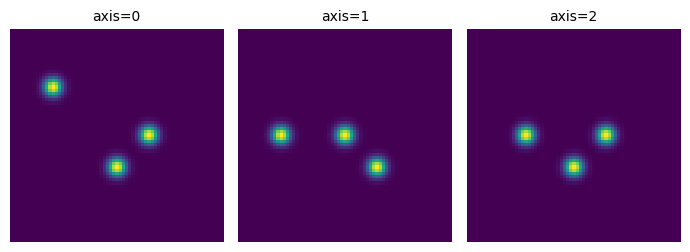

	 rotated


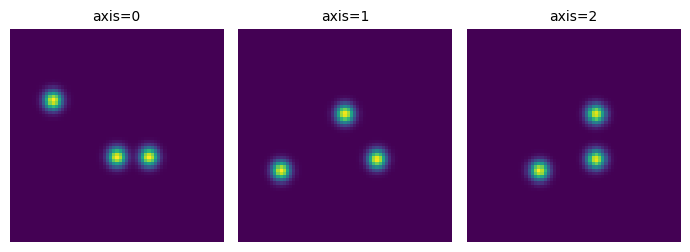

In [6]:
thetas = np.linspace(0, np.pi, L, endpoint=True)
phis = np.linspace(0, 2*np.pi, L, endpoint=False)

omega = np.deg2rad(0)
theta = np.deg2rad(45)
phi = np.deg2rad(0)

G = transforms.rotate_voxel_zyz(F, omega, theta, phi, order=1)
G = signals.Signal(G, d=3).preprocess_signals()[0]

print('\t original')
plots.orthogonal_2D_projection_plot(F)
print('\t rotated')
plots.orthogonal_2D_projection_plot(G)

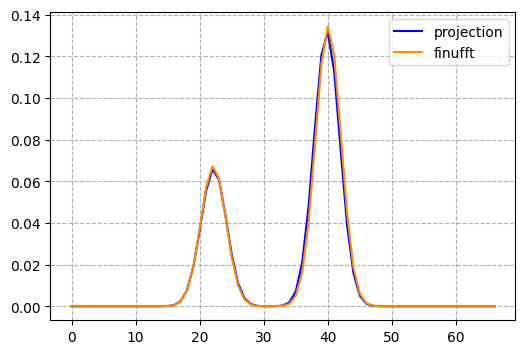

 theta gt:  45.0
theta idx:  43.63636363636363
   phi gt:  0.0
  phi idx:  0.0


In [7]:
phi_idx = np.argmin(abs(phis - abs(phi)))
theta_idx = np.argmin(abs(thetas - abs(theta)))

plt.figure(figsize=(6,4))

plt.plot(np.sum(G, axis=(0,2)), color='blue', label='projection')

plt.plot(z_rt[phi_idx, :, theta_idx], color='darkorange', label='finufft')

plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

print(' theta gt: ', np.rad2deg(theta))
print('theta idx: ', np.rad2deg(thetas)[theta_idx])
print('   phi gt: ', np.rad2deg(phi))
print('  phi idx: ', np.rad2deg(phis)[phi_idx])